In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
# Read the original CSV file
sales = pd.read_csv("sales_raw.csv")

# Show the first five rows
display(sales.head())

# Show the number of rows and columns
print("Dataset shape:", sales.shape)

# Show all column names
print("\\nColumn names:")
print(sales.columns.tolist())

# Show the data type of each column
print("\\nData types:")
print(sales.dtypes)

# Count missing values in each column
print("\\nMissing values:")
print(sales.isna().sum())

# Count fully duplicated rows
print("\\nDuplicate rows:", sales.duplicated().sum())

,transaction_id,sale_date,region,category,quantity,unit_price
0,1001,10/1/2026,North,food,2.0,120
1,1002,10/1/2026,South,Books,1.0,250
2,1003,10/2/2026,North,Food,3.0,110
3,1004,10/2/2026,East,Stationery,4.0,50
4,1005,10/3/2026,SOUTH,books,2.0,250


Dataset shape: (21, 6)
\nColumn names:
['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price']
\nData types:
transaction_id      int64
sale_date             str
region                str
category              str
quantity          float64
unit_price            str
dtype: object
\nMissing values:
transaction_id    0
sale_date         0
region            1
category          0
quantity          1
unit_price        1
dtype: int64
\nDuplicate rows: 1


In [5]:
# Keep a copy so the original data stays unchanged
clean_sales = sales.copy()

# Remove extra spaces and make text consistent
clean_sales["region"] = clean_sales["region"].astype("string").str.strip().str.title()
clean_sales["category"] = clean_sales["category"].astype("string").str.strip().str.title()

# Fill missing region names
clean_sales["region"] = clean_sales["region"].fillna("Unknown")

# Convert columns to the correct data types
clean_sales["sale_date"] = pd.to_datetime(clean_sales["sale_date"], errors="coerce")
clean_sales["quantity"] = pd.to_numeric(clean_sales["quantity"], errors="coerce")
clean_sales["unit_price"] = pd.to_numeric(clean_sales["unit_price"], errors="coerce")

# Remove exact duplicate rows
clean_sales = clean_sales.drop_duplicates()

# A quantity must be greater than zero
clean_sales.loc[clean_sales["quantity"] <= 0, "quantity"] = np.nan

# Find unusually high prices using the IQR method
q1 = clean_sales["unit_price"].quantile(0.25)
q3 = clean_sales["unit_price"].quantile(0.75)
iqr = q3 - q1
upper_limit = q3 + (1.5 * iqr)

# Replace prices above the upper limit with a missing value
clean_sales.loc[clean_sales["unit_price"] > upper_limit, "unit_price"] = np.nan

# Fill missing quantities with the median quantity
clean_sales["quantity"] = clean_sales["quantity"].fillna(
    clean_sales["quantity"].median()
)

# Fill missing prices with the median price of the same category
category_median = clean_sales.groupby("category")["unit_price"].transform("median")
clean_sales["unit_price"] = clean_sales["unit_price"].fillna(category_median)

# Use the overall median only if a category has no available prices
clean_sales["unit_price"] = clean_sales["unit_price"].fillna(
    clean_sales["unit_price"].median()
)

# Quantity represents a count, so convert it to whole numbers
clean_sales["quantity"] = clean_sales["quantity"].astype(int)

# Compare the number of rows before and after cleaning
print("Rows before cleaning:", len(sales))
print("Rows after cleaning:", len(clean_sales))
print("Rows removed:", len(sales) - len(clean_sales))

# Check the cleaned data
display(clean_sales.head())
print("\\nMissing values after cleaning:")
print(clean_sales.isna().sum())

Rows before cleaning: 21
Rows after cleaning: 20
Rows removed: 1


,transaction_id,sale_date,region,category,quantity,unit_price
0,1001,2026-10-01,North,Food,2,120.0
1,1002,2026-10-01,South,Books,1,250.0
2,1003,2026-10-02,North,Food,3,110.0
3,1004,2026-10-02,East,Stationery,4,50.0
4,1005,2026-10-03,South,Books,2,250.0


\nMissing values after cleaning:
transaction_id    0
sale_date         1
region            0
category          0
quantity          0
unit_price        0
dtype: int64


In [6]:
# Calculate revenue for each sale
clean_sales["revenue"] = clean_sales["quantity"] * clean_sales["unit_price"]

# Total revenue by region
region_summary = clean_sales.groupby("region")["revenue"].sum().sort_values(
    ascending=False
)

print("Revenue by region:")
display(region_summary)

# Total revenue by category
category_summary = clean_sales.groupby("category")["revenue"].sum().sort_values(
    ascending=False
)

print("Revenue by category:")
display(category_summary)

Revenue by region:


region
North      1520.0
South      1395.0
West       1390.0
East        970.0
Unknown     400.0
Name: revenue, dtype: float64

Revenue by category:


category
Food          2695.0
Books         2370.0
Stationery     610.0
Name: revenue, dtype: float64

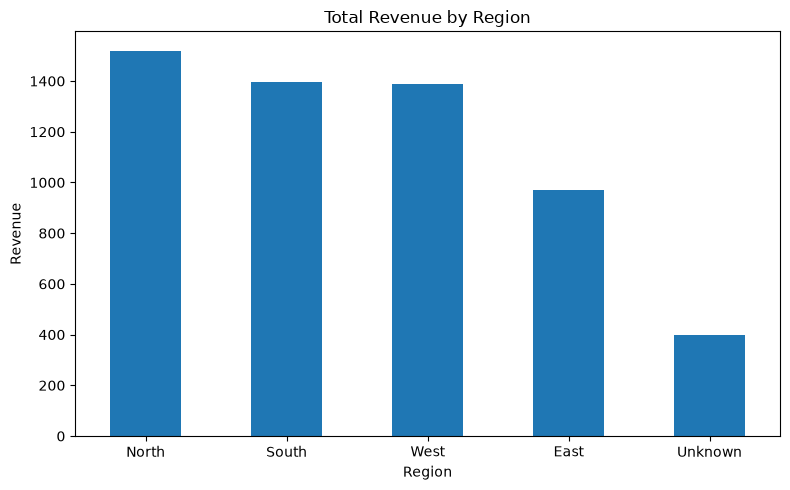

In [7]:
plt.figure(figsize=(8, 5))
region_summary.plot(kind="bar")

plt.title("Total Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.xticks(rotation=0)
plt.tight_layout()

# Save the chart as an image
plt.savefig("revenue_by_region.png", dpi=150)
plt.show()

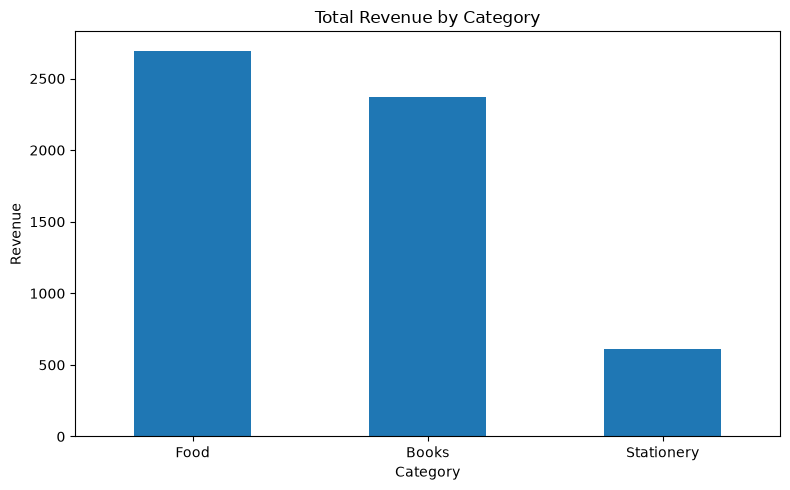

In [8]:
plt.figure(figsize=(8, 5))
category_summary.plot(kind="bar")

plt.title("Total Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Revenue")
plt.xticks(rotation=0)
plt.tight_layout()

# Save the chart as an image
plt.savefig("revenue_by_category.png", dpi=150)
plt.show()

In [9]:
clean_sales.to_csv("cleaned_sales.csv", index=False)

print("Cleaned data saved as cleaned_sales.csv")

Cleaned data saved as cleaned_sales.csv


In [10]:
# Read the cleaned data created in Part A
updated_sales = pd.read_csv("cleaned_sales.csv")

# Add a tax column equal to 5% of revenue
updated_sales["tax_amount"] = updated_sales["revenue"] * 0.05

# Show the first five rows
display(updated_sales.head())

,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1001,2026-10-01,North,Food,2,120.0,240.0,12.0
1,1002,2026-10-01,South,Books,1,250.0,250.0,12.5
2,1003,2026-10-02,North,Food,3,110.0,330.0,16.5
3,1004,2026-10-02,East,Stationery,4,50.0,200.0,10.0
4,1005,2026-10-03,South,Books,2,250.0,500.0,25.0


In [11]:
# Select Books rows and increase their unit price by 10%
books_rows = updated_sales["category"].str.lower() == "books"
updated_sales.loc[books_rows, "unit_price"] *= 1.10

# Recalculate revenue after changing prices
updated_sales["revenue"] = (
    updated_sales["quantity"] * updated_sales["unit_price"]
)

# Recalculate tax using the updated revenue
updated_sales["tax_amount"] = updated_sales["revenue"] * 0.05

display(updated_sales.head())

,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1001,2026-10-01,North,Food,2,120.0,240.0,12.00
1,1002,2026-10-01,South,Books,1,275.0,275.0,13.75
2,1003,2026-10-02,North,Food,3,110.0,330.0,16.50
3,1004,2026-10-02,East,Stationery,4,50.0,200.0,10.00
4,1005,2026-10-03,South,Books,2,275.0,550.0,27.50


In [12]:
# Transaction ID selected for removal
transaction_to_remove = 1002

# Keep rows that do not have this transaction ID
updated_sales = updated_sales[
    updated_sales["transaction_id"] != transaction_to_remove
].copy()

print("Transaction removed:", transaction_to_remove)
print("Rows remaining:", len(updated_sales))

Transaction removed: 1002
Rows remaining: 19


In [13]:
# Add a temporary column
updated_sales["review_status"] = "Pending review"

# Remove the temporary column
updated_sales = updated_sales.drop(columns=["review_status"])

# Check the remaining columns
print(updated_sales.columns.tolist())

['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price', 'revenue', 'tax_amount']


In [14]:
# Save the updated data
updated_sales.to_csv("sales_updated.csv", index=False)

# Read the saved CSV file again
check_sales = pd.read_csv("sales_updated.csv")

# Show the first five rows
display(check_sales.head())

# Show the final column names
print("Final column names:")
print(check_sales.columns.tolist())

print("\\nUpdated file saved and checked successfully.")

,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1001,2026-10-01,North,Food,2,120.0,240.0,12.0
1,1003,2026-10-02,North,Food,3,110.0,330.0,16.5
2,1004,2026-10-02,East,Stationery,4,50.0,200.0,10.0
3,1005,2026-10-03,South,Books,2,275.0,550.0,27.5
4,1006,2026-10-03,West,Food,2,130.0,260.0,13.0


Final column names:
['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price', 'revenue', 'tax_amount']
\nUpdated file saved and checked successfully.
